# Validate field / resized / bicubic image transformations

This notebook validates the image transformations used by the **field experiment**
(`main_field.py`) by running the *exact* functions the experiment uses and displaying
the images that are actually passed to the model.

For every sample the worker (`src/models.py`) builds three variants with
`src.utils.build_field_images`:

1. **field** – the original embedded in a larger blank canvas (`ImageProcessor.add_white_field`).
2. **resized** – the plain original downscaled by the same coefficient the field image
   experiences during that model's preprocessing (`image_resized_size_px / image_original_size_px`).
3. **bicubic** – the *resized* image upsampled back to the original size via bicubic
   interpolation (original resolution, but with the detail lost in the downscale).

The **field** image is architecture-independent. The **resized/bicubic** images depend
only on the preprocessing coefficient, so we first validate the whole pipeline with a
lightweight stand-in processor (no model weights, section 2) and then optionally
cross-check against the real processors of all four model families (section 3).

In [1]:
import sys
from pathlib import Path

project_root = Path().resolve().parent  # notebooks/ -> project root
sys.path.insert(0, str(project_root))

In [2]:
from PIL import Image, ImageDraw
import numpy as np
import math
import matplotlib.pyplot as plt

# The exact functions used by the experiment
from src.utils import ImageProcessor, build_field_images, get_preprocessed_size
from src.benchmarks_original import MMVetDataset, MMEvalDataset, MathVerseDataset, MMStar, CharXiv

/home/colligo/Waldo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load a sample image

We load a sample through the same dataset classes the experiment uses
(`src.benchmarks_original`). If the datasets are not available (e.g. offline / no HF
access), we fall back to a synthetic image with fine detail and small text so the
effect of down/up-scaling is clearly visible.

In [3]:
BENCHMARK_CLASSES = {
    "mmvet": (MMVetDataset, "whyu/mm-vet"),
    "mathverse": (MathVerseDataset, "AI4Math/MathVerse"),
    "mmstar": (MMStar, "Lin-Chen/MMStar"),
    "charxiv": (CharXiv, "princeton-nlp/charxiv"),
    "mmeval": (MMEvalDataset, "darkyarding/MME"),
}


def make_synthetic_image(size=(768, 512)):
    """A detailed test card: grid, diagonals and small text (detail survives poorly
    under aggressive downscaling, which is exactly what we want to inspect)."""
    w, h = size
    img = Image.new("RGB", size, (255, 255, 255))
    d = ImageDraw.Draw(img)
    for x in range(0, w, 16):
        d.line([(x, 0), (x, h)], fill=(220, 220, 220), width=1)
    for y in range(0, h, 16):
        d.line([(0, y), (w, y)], fill=(220, 220, 220), width=1)
    d.line([(0, 0), (w, h)], fill=(200, 40, 40), width=2)
    d.line([(0, h), (w, 0)], fill=(40, 40, 200), width=2)
    for i in range(0, w, 48):
        d.text((i + 2, 4), "3.14", fill=(0, 0, 0))
    d.rectangle([w // 2 - 40, h // 2 - 25, w // 2 + 40, h // 2 + 25], outline=(0, 150, 0), width=3)
    d.text((w // 2 - 30, h // 2 - 8), "WALDO", fill=(0, 120, 0))
    return img


def load_sample(benchmark="mmvet", index=0):
    try:
        cls, name = BENCHMARK_CLASSES[benchmark.lower()]
        ds = cls(dataset_name=name, field=0, position="center")
        item = ds[index]
        img = item["image"].convert("RGB")
        print(f"Loaded sample #{index} from {benchmark}: size={img.size}, question={item['question'][:80]!r}")
        return img
    except Exception as e:
        print(f"Could not load benchmark '{benchmark}' ({e}); using synthetic image instead.")
        return make_synthetic_image()


sample_image = load_sample("mmvet", 0)
print("Original size (W, H):", sample_image.size)

Loaded sample #0 from mmvet: size=(750, 563), question='How to cook this dish?'
Original size (W, H): (750, 563)


## Display helper

Renders images side by side at their true *relative* pixel scale, with the pixel size in each title.

In [4]:
def show_row(items, title=None, max_in_px=6.0):
    """items: list of (label, PIL.Image). Panels are scaled to relative pixel size."""
    widths = [im.size[0] for _, im in items]
    wmax = max(widths)
    fig, axes = plt.subplots(
        1, len(items),
        figsize=(max_in_px * len(items), max_in_px),
        gridspec_kw={"width_ratios": [max(w / wmax, 0.15) for w in widths]},
    )
    if len(items) == 1:
        axes = [axes]
    for ax, (label, im) in zip(axes, items):
        ax.imshow(np.asarray(im))
        ax.set_title(f"{label}\n{im.size[0]}x{im.size[1]} px", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
    if title:
        fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

## 1. Field transform — architecture-independent

`ImageProcessor.add_white_field` embeds the original in a larger blank canvas. This is
exactly the image passed to the model for the field experiment and it does **not**
depend on the model architecture. Below: growing field percentages, plus the three
supported positions.

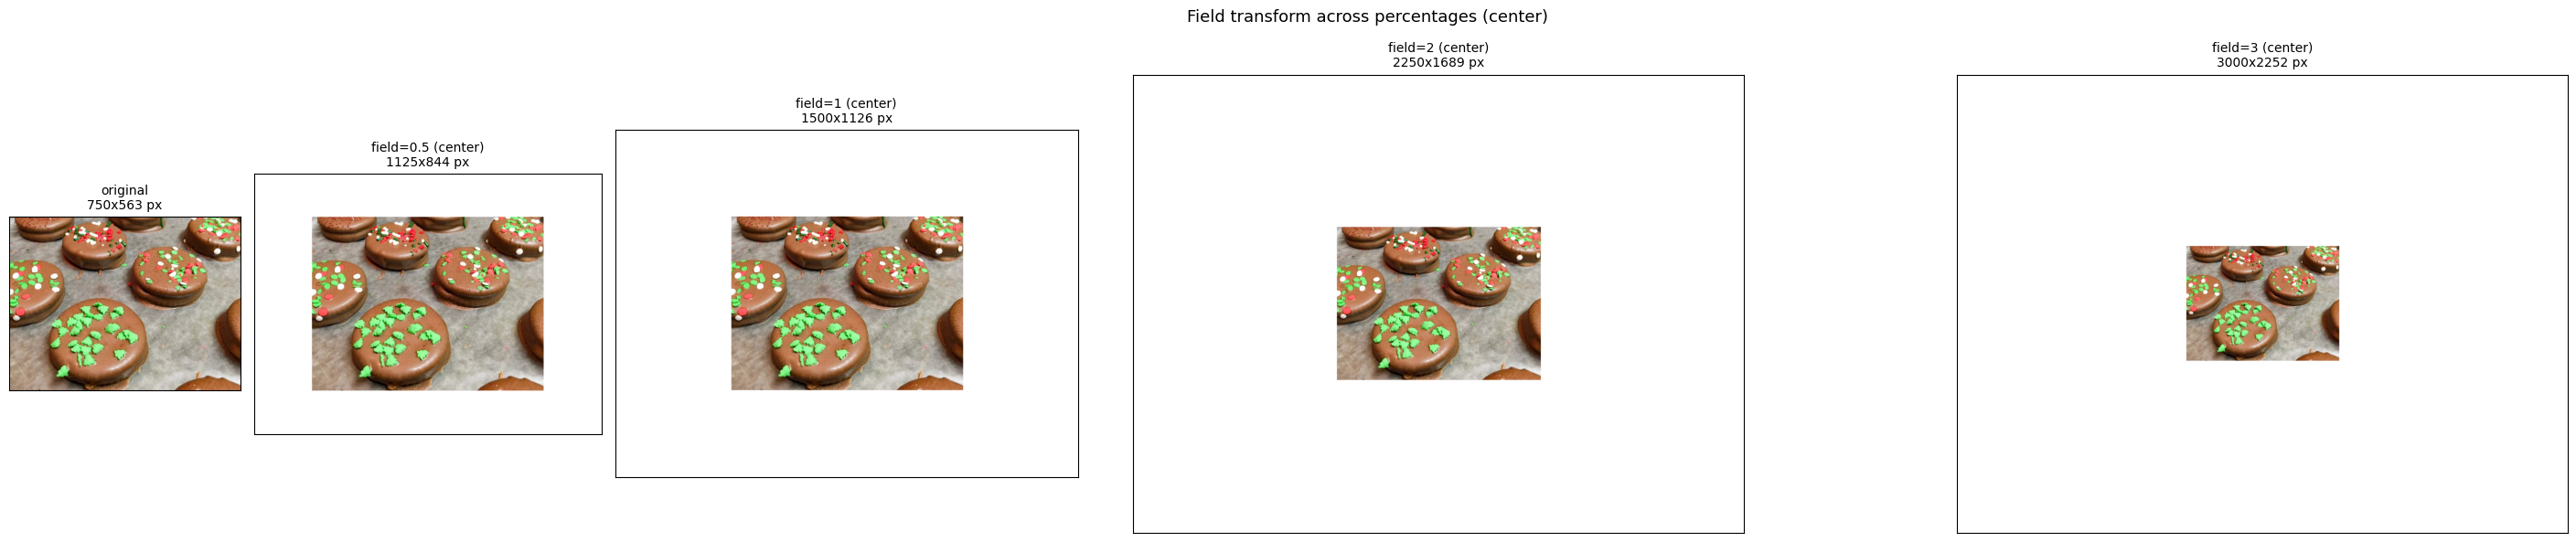

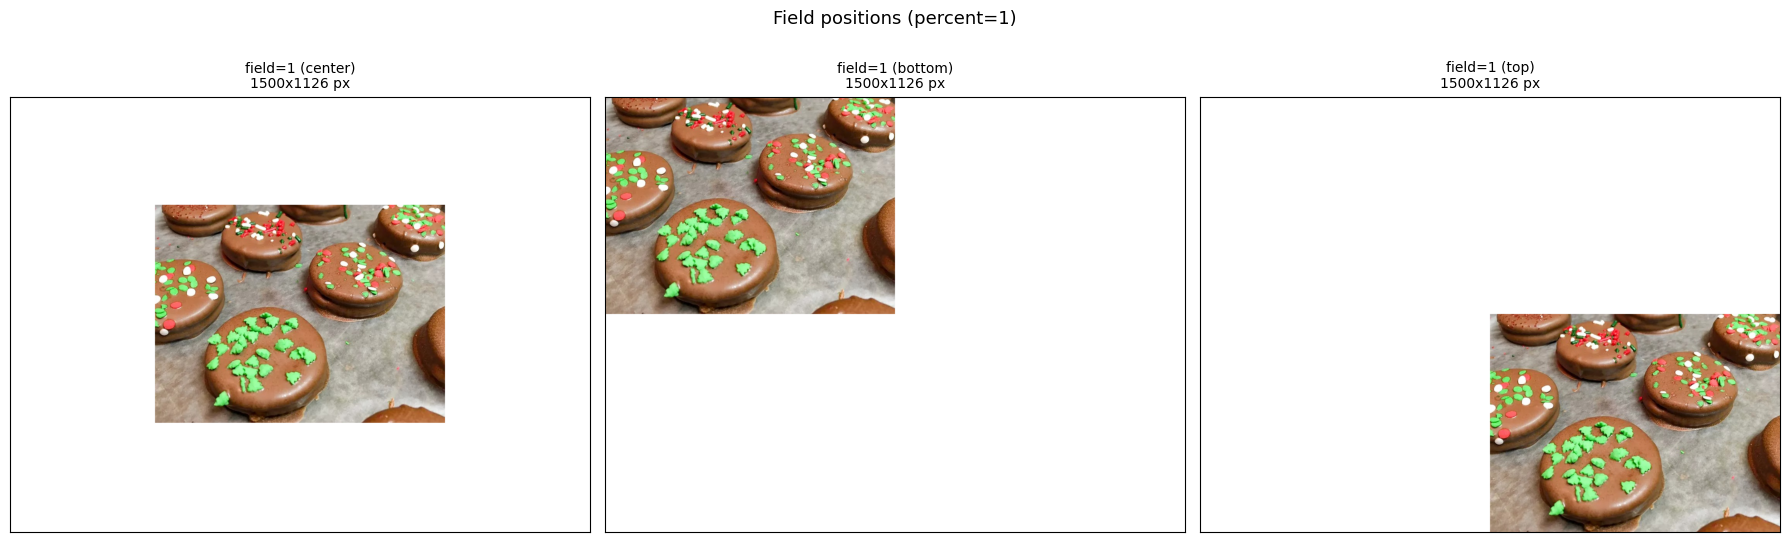

In [5]:
field_values = [0, 0.5, 1, 2, 3]
row = [("original", sample_image)]
for f in field_values:
    if f == 0:
        continue
    fimg = ImageProcessor.add_white_field(sample_image, percent=f, position="center")
    row.append((f"field={f} (center)", fimg))
show_row(row, title="Field transform across percentages (center)")

positions = ["center", "bottom", "top"]
row = [(f"field=1 ({p})", ImageProcessor.add_white_field(sample_image, percent=1, position=p)) for p in positions]
show_row(row, title="Field positions (percent=1)")

## 2. Full pipeline (field / resized / bicubic) — no model weights

`build_field_images` is the single function the worker calls per sample. It returns the
three images passed to the model plus the size metadata.

To keep this architecture-independent and runnable without downloading any checkpoint,
we pass a lightweight **stand-in image processor** that implements a generic
"max-pixels" resize using Qwen's `smart_resize` rule and the same `image_grid_thw` API
`get_preprocessed_size` reads. Only the *size source* is a stand-in — the transformation
functions are identical to the experiment. Lower `MAX_PIXELS` to force more aggressive
downscaling.

In [6]:
IMAGE_FACTOR = 28   # patch_size (14) * merge_size (2), Qwen convention
PATCH_SIZE = 14


def _round_by_factor(n, f): return round(n / f) * f
def _floor_by_factor(n, f): return math.floor(n / f) * f
def _ceil_by_factor(n, f): return math.ceil(n / f) * f


def smart_resize(h, w, factor=IMAGE_FACTOR, min_pixels=56 * 56, max_pixels=1024 * 1024):
    """Qwen smart_resize: multiples of `factor`, aspect-preserving, within pixel budget."""
    h_bar = max(factor, _round_by_factor(h, factor))
    w_bar = max(factor, _round_by_factor(w, factor))
    if h_bar * w_bar > max_pixels:
        beta = math.sqrt((h * w) / max_pixels)
        h_bar = max(factor, _floor_by_factor(h / beta, factor))
        w_bar = max(factor, _floor_by_factor(w / beta, factor))
    elif h_bar * w_bar < min_pixels:
        beta = math.sqrt(min_pixels / (h * w))
        h_bar = _ceil_by_factor(h * beta, factor)
        w_bar = _ceil_by_factor(w * beta, factor)
    return h_bar, w_bar


class StandInImageProcessor:
    """Emulates the Qwen image-processor API that get_preprocessed_size() reads."""
    patch_size = PATCH_SIZE

    def __init__(self, max_pixels=1024 * 1024, min_pixels=56 * 56):
        self.max_pixels = max_pixels
        self.min_pixels = min_pixels

    def __call__(self, images, return_tensors=None):
        img = images[0] if isinstance(images, (list, tuple)) else images
        w, h = img.size
        H, W = smart_resize(h, w, IMAGE_FACTOR, self.min_pixels, self.max_pixels)
        return {"image_grid_thw": [[1, H // self.patch_size, W // self.patch_size]]}


class StandInProcessor:
    def __init__(self, **kw):
        self.image_processor = StandInImageProcessor(**kw)


stand_in = StandInProcessor(max_pixels=1024 * 1024)
# model_name contains "qwen" so get_preprocessed_size uses the image_grid_thw path
STAND_IN_NAME = "qwen-stand-in"

# sanity check the size read-back matches smart_resize
_w, _h = sample_image.size
print("get_preprocessed_size(original) ->", get_preprocessed_size(stand_in, STAND_IN_NAME, sample_image))
print("smart_resize(original)          ->", tuple(reversed(smart_resize(_h, _w, IMAGE_FACTOR, stand_in.image_processor.min_pixels, stand_in.image_processor.max_pixels))))

get_preprocessed_size(original) -> (756, 560)
smart_resize(original)          -> (756, 560)


[qwen-stand-in] field=0 position=center
    image_original_size_px: {'width': 750, 'height': 563}
    image_field_size_px: {'width': 750, 'height': 563}
    image_resized_size_px: {'width': 756, 'height': 560}
    rescaling_coefficient: {'width': 1.008, 'height': 0.9946714031971581}
    image_resized_experiment_size_px: {'width': 756, 'height': 560}


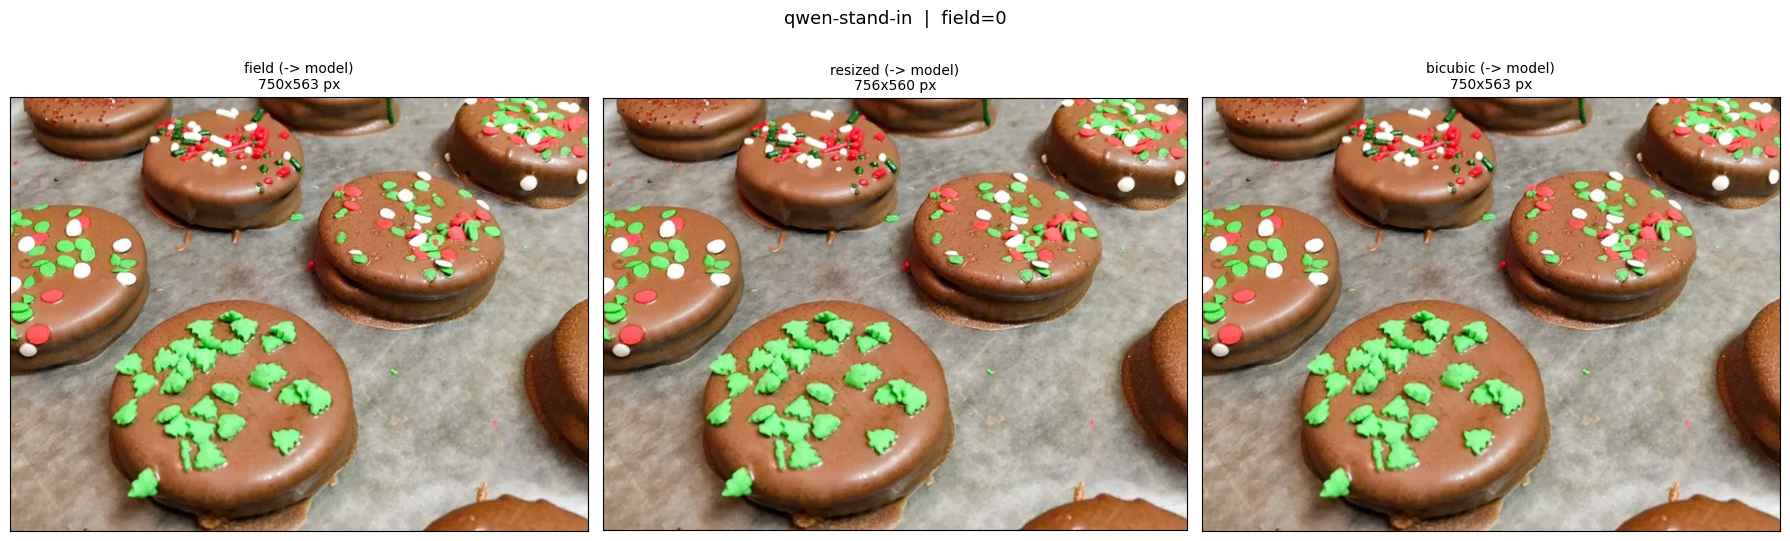

[qwen-stand-in] field=1 position=center
    image_original_size_px: {'width': 750, 'height': 563}
    image_field_size_px: {'width': 1500, 'height': 1126}
    image_resized_size_px: {'width': 1176, 'height': 868}
    rescaling_coefficient: {'width': 0.784, 'height': 0.7708703374777975}
    image_resized_experiment_size_px: {'width': 588, 'height': 434}


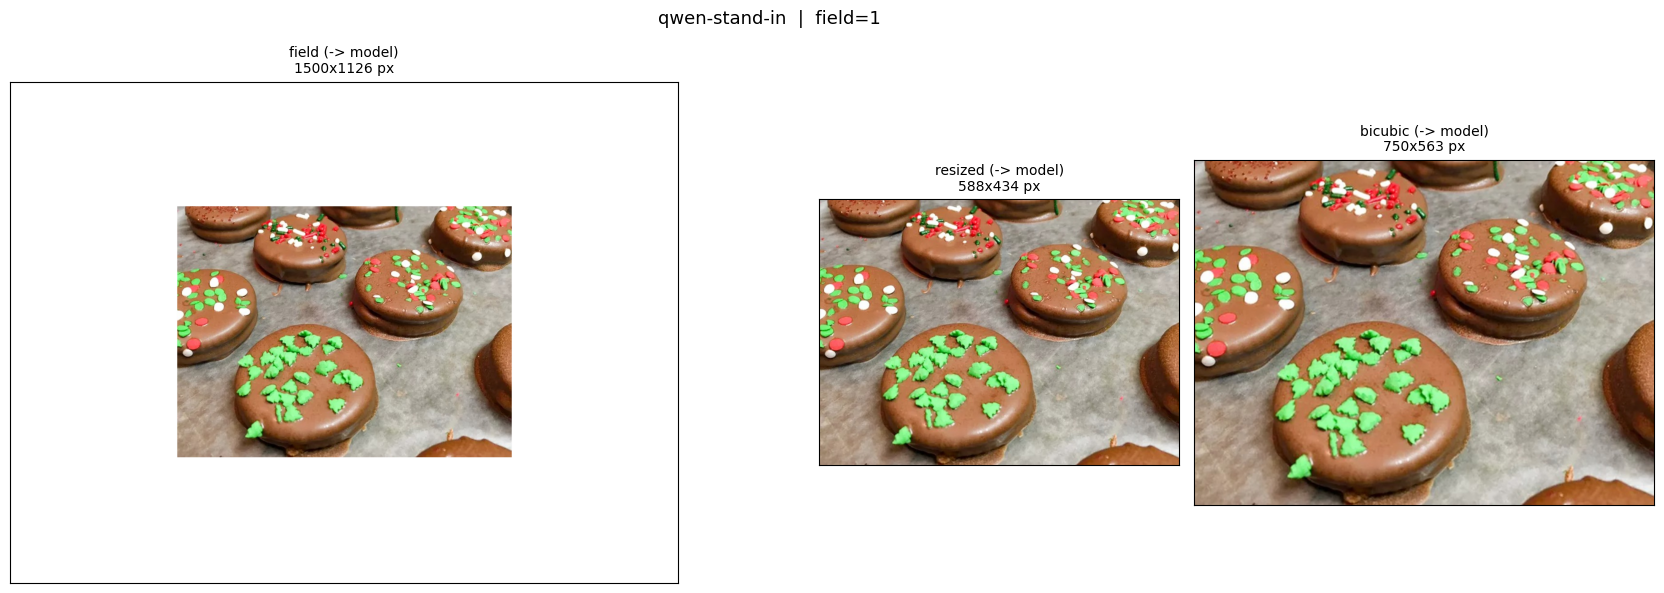

[qwen-stand-in] field=3 position=center
    image_original_size_px: {'width': 750, 'height': 563}
    image_field_size_px: {'width': 3000, 'height': 2252}
    image_resized_size_px: {'width': 1176, 'height': 868}
    rescaling_coefficient: {'width': 0.392, 'height': 0.38543516873889877}
    image_resized_experiment_size_px: {'width': 294, 'height': 217}


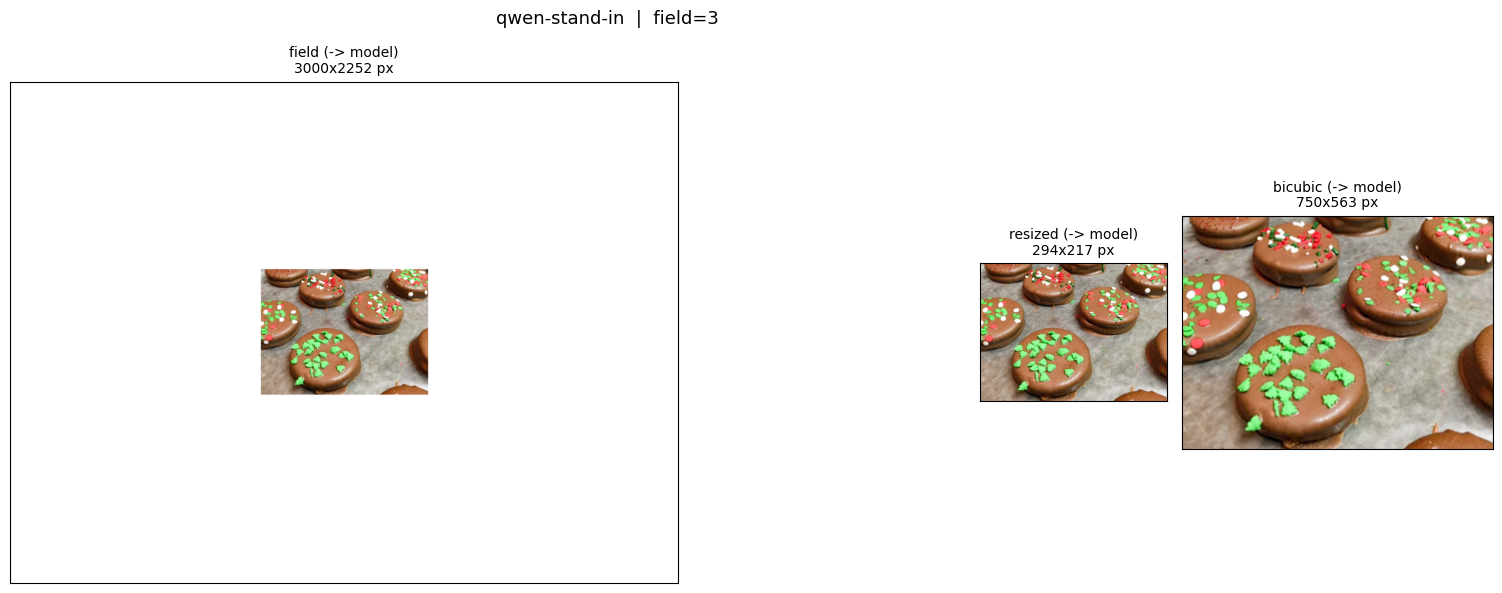

In [7]:
def validate(processor, model_name, image, field, position="center"):
    field_img, resized_img, bicubic_img, info = build_field_images(
        processor, model_name, image, field, position
    )
    print(f"[{model_name}] field={field} position={position}")
    for k, v in info.items():
        print(f"    {k}: {v}")
    show_row(
        [("field (-> model)", field_img),
         ("resized (-> model)", resized_img),
         ("bicubic (-> model)", bicubic_img)],
        title=f"{model_name}  |  field={field}",
    )
    return field_img, resized_img, bicubic_img, info


for f in [0, 1, 3]:
    validate(stand_in, STAND_IN_NAME, sample_image, field=f, position="center")

## 3. (Optional) Cross-check on real model processors

Runs the same `build_field_images` with the actual image processors of all four
families. Only the *processor* is loaded (no model weights), but this still requires
Hugging Face access; gated models (Llama-3.2) need a token. Each family is wrapped in
try/except and skipped with a message if unavailable.

Qwen2-VL -> Qwen/Qwen2-VL-2B-Instruct


The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


[Qwen/Qwen2-VL-2B-Instruct] field=2 position=center
    image_original_size_px: {'width': 750, 'height': 563}
    image_field_size_px: {'width': 2250, 'height': 1689}
    image_resized_size_px: {'width': 2240, 'height': 1680}
    rescaling_coefficient: {'width': 0.9955555555555555, 'height': 0.9946714031971581}
    image_resized_experiment_size_px: {'width': 747, 'height': 560}


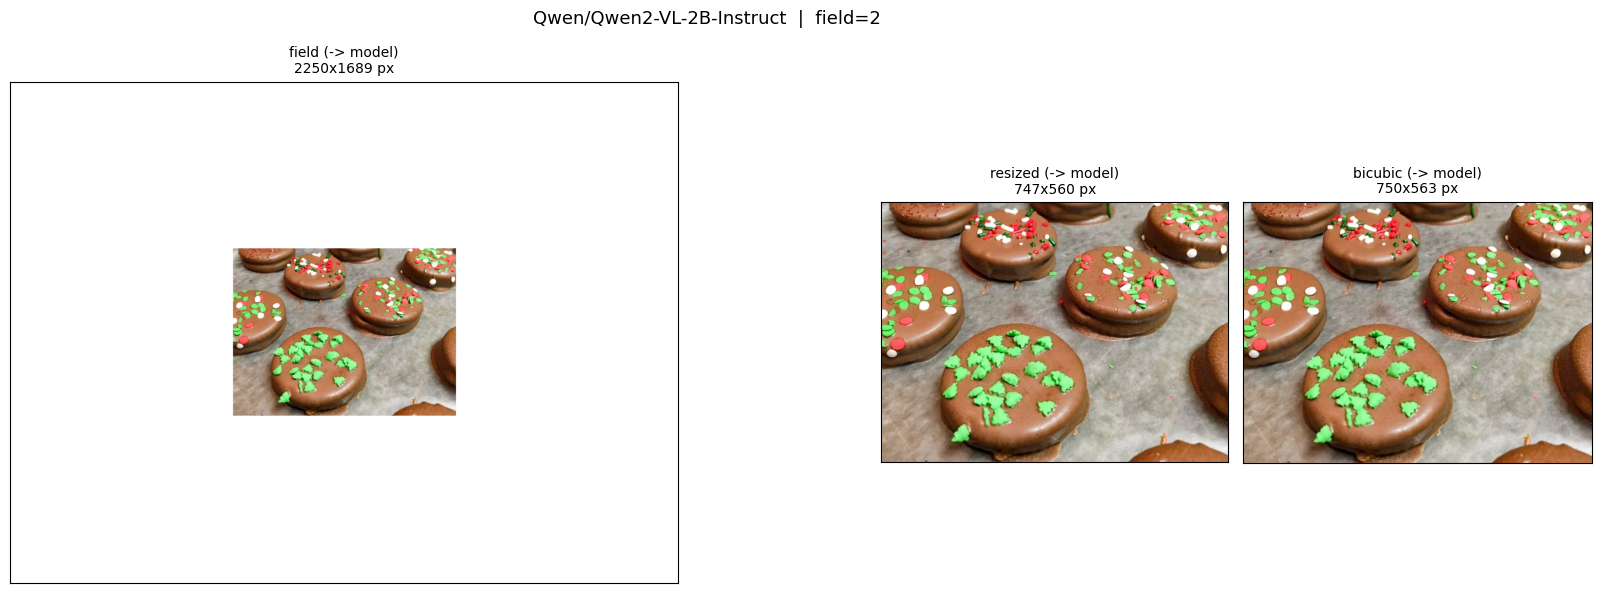

LLaVA-1.5 -> llava-hf/llava-1.5-7b-hf


The image processor of type `CLIPImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


[llava-hf/llava-1.5-7b-hf] field=2 position=center
    image_original_size_px: {'width': 750, 'height': 563}
    image_field_size_px: {'width': 2250, 'height': 1689}
    image_resized_size_px: {'width': 336, 'height': 336}
    rescaling_coefficient: {'width': 0.14933333333333335, 'height': 0.1989342806394316}
    image_resized_experiment_size_px: {'width': 112, 'height': 112}


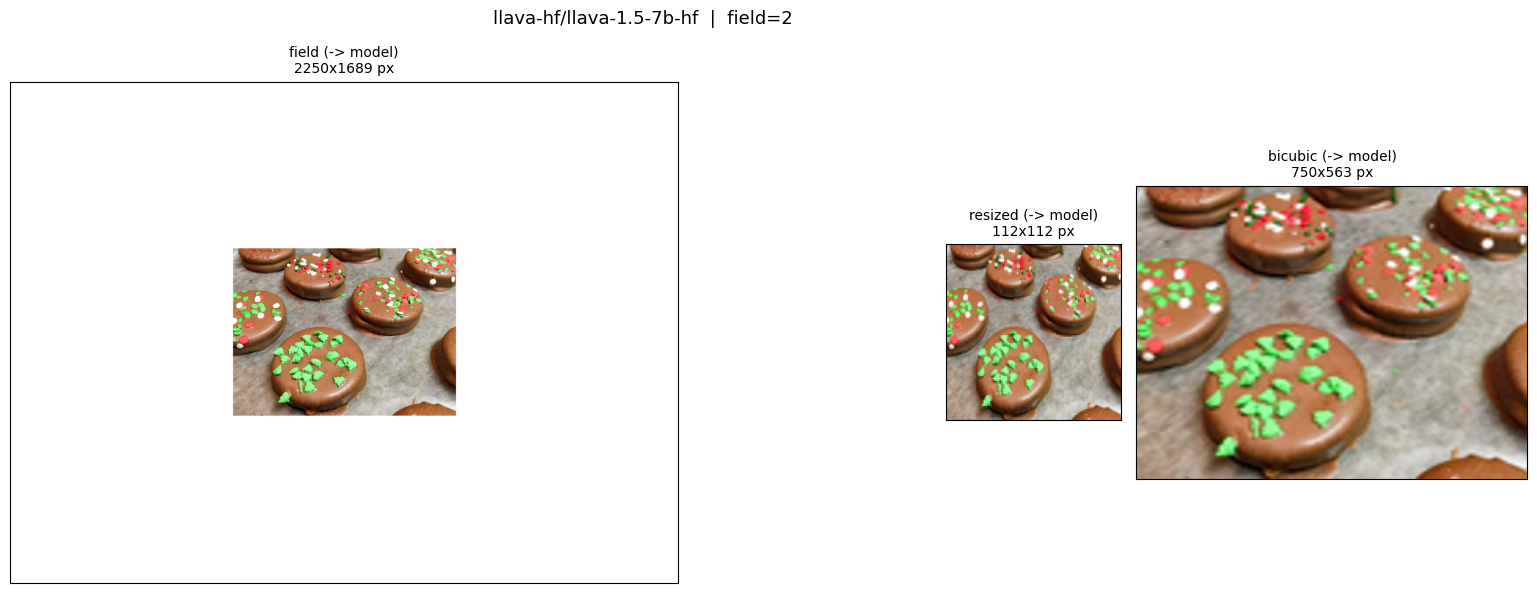

Pixtral -> mistral-community/pixtral-12b


The image processor of type `PixtralImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


[mistral-community/pixtral-12b] field=2 position=center
    image_original_size_px: {'width': 750, 'height': 563}
    image_field_size_px: {'width': 2250, 'height': 1689}
    image_resized_size_px: {'width': 1024, 'height': 768}
    rescaling_coefficient: {'width': 0.45511111111111113, 'height': 0.4547069271758437}
    image_resized_experiment_size_px: {'width': 341, 'height': 256}


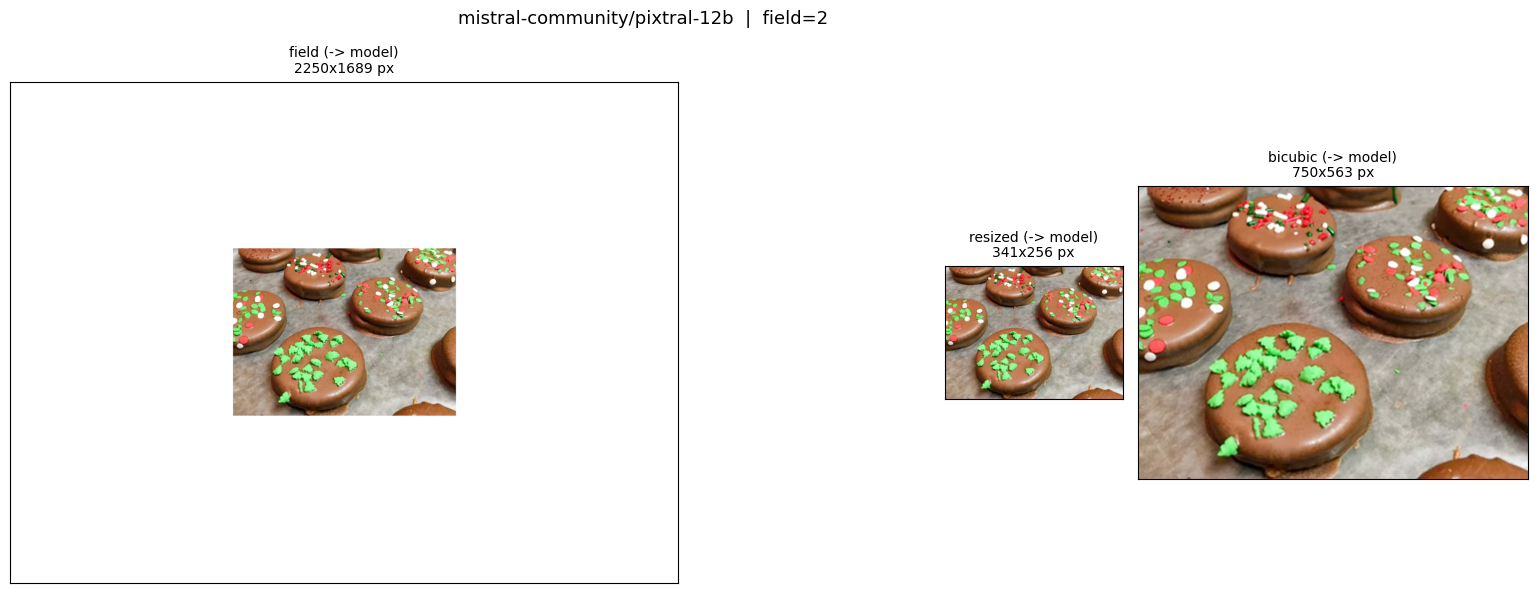

Llama-3.2 -> meta-llama/Llama-3.2-11B-Vision-Instruct


The image processor of type `MllamaImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


[meta-llama/Llama-3.2-11B-Vision-Instruct] field=2 position=center
    image_original_size_px: {'width': 750, 'height': 563}
    image_field_size_px: {'width': 2250, 'height': 1689}
    image_resized_size_px: {'width': 1120, 'height': 841}
    rescaling_coefficient: {'width': 0.49777777777777776, 'height': 0.4979277679100059}
    image_resized_experiment_size_px: {'width': 373, 'height': 280}


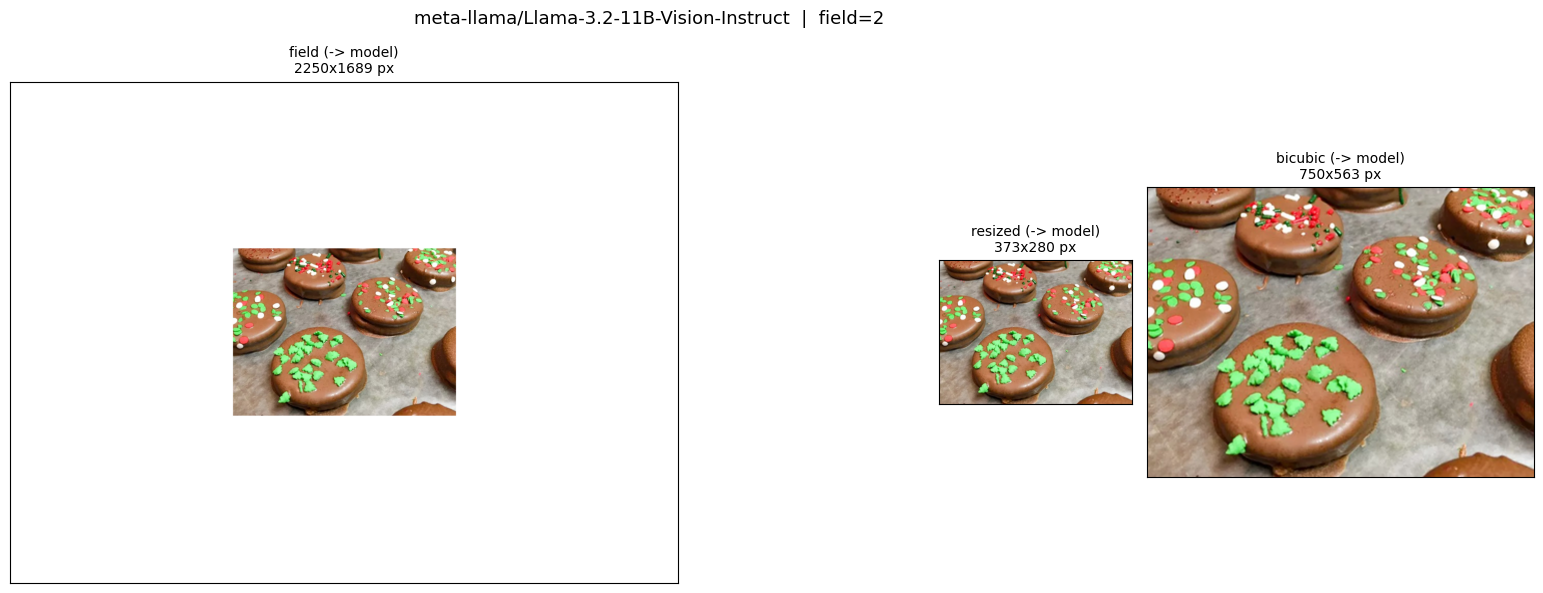

In [8]:
from transformers import AutoProcessor

REAL_MODELS = {
    "Qwen2-VL":   "Qwen/Qwen2-VL-2B-Instruct",
    "LLaVA-1.5":  "llava-hf/llava-1.5-7b-hf",
    "Pixtral":    "mistral-community/pixtral-12b",
    "Llama-3.2":  "meta-llama/Llama-3.2-11B-Vision-Instruct",
}

FIELD_FOR_REAL = 2

for family, model_name in REAL_MODELS.items():
    print("=" * 70)
    print(family, "->", model_name)
    try:
        processor = AutoProcessor.from_pretrained(model_name, trust_remote_code=True)
    except Exception as e:
        print(f"  SKIPPED ({type(e).__name__}): {e}")
        continue
    try:
        validate(processor, model_name, sample_image, field=FIELD_FOR_REAL, position="center")
    except Exception as e:
        print(f"  build/display failed ({type(e).__name__}): {e}")

## 4. Numeric validation of the invariants

Checks the geometric guarantees of the pipeline for a range of field values (using the
stand-in processor):

* field image size == `round(original * (1 + field))` per dimension,
* `image_original_size_px` == the field image size fed to the processor,
* resized image size == `round(original * coefficient)` per dimension,
* bicubic image size == original size,
* coefficient == `image_resized_size_px / image_original_size_px`.

In [9]:
ow, oh = sample_image.size
rows = []
all_ok = True

for f in [0, 0.5, 1, 2, 3, 5]:
    field_img, resized_img, bicubic_img, info = build_field_images(
        stand_in, STAND_IN_NAME, sample_image, field=f, position="center"
    )
    fw, fh = info["image_field_size_px"]["width"], info["image_field_size_px"]["height"]
    rw, rh = info["image_resized_size_px"]["width"], info["image_resized_size_px"]["height"]
    cx, cy = info["rescaling_coefficient"]["width"], info["rescaling_coefficient"]["height"]
    tw, th = info["image_resized_experiment_size_px"]["width"], info["image_resized_experiment_size_px"]["height"]

    exp_field = (round(ow * (1 + f)), round(oh * (1 + f))) if f else (ow, oh)
    checks = {
        "field==(1+f)*orig": field_img.size == exp_field,
        "orig_px==field.size": (fw, fh) == field_img.size,
        "resized==round(coef*orig)": resized_img.size == (max(1, round(ow * cx)), max(1, round(oh * cy))),
        "resized.size==info": resized_img.size == (tw, th),
        "bicubic==orig": bicubic_img.size == (ow, oh),
        "coef==resized/orig": abs(cx - rw / fw) < 1e-9 and abs(cy - rh / fh) < 1e-9,
    }
    ok = all(checks.values())
    all_ok &= ok
    rows.append((f, field_img.size, (rw, rh), (round(cx, 3), round(cy, 3)),
                 resized_img.size, bicubic_img.size, "OK" if ok else "FAIL " + str(checks)))

print(f"{'field':>6} | {'field_px':>12} | {'resized_px':>12} | {'coef':>14} | {'resized_img':>12} | {'bicubic_img':>12} | status")
print("-" * 110)
for r in rows:
    print(f"{r[0]:>6} | {str(r[1]):>12} | {str(r[2]):>12} | {str(r[3]):>14} | {str(r[4]):>12} | {str(r[5]):>12} | {r[6]}")

assert all_ok, "Some invariants failed - see status column above"
print("\nAll invariants hold.")

 field |     field_px |   resized_px |           coef |  resized_img |  bicubic_img | status
--------------------------------------------------------------------------------------------------------------
     0 |   (750, 563) |   (756, 560) | (1.008, 0.995) |   (756, 560) |   (750, 563) | OK
   0.5 |  (1125, 844) |  (1120, 840) | (0.996, 0.995) |   (747, 560) |   (750, 563) | OK
     1 | (1500, 1126) |  (1176, 868) | (0.784, 0.771) |   (588, 434) |   (750, 563) | OK
     2 | (2250, 1689) |  (1176, 868) | (0.523, 0.514) |   (392, 289) |   (750, 563) | OK
     3 | (3000, 2252) |  (1176, 868) | (0.392, 0.385) |   (294, 217) |   (750, 563) | OK
     5 | (4500, 3378) |  (1176, 868) | (0.261, 0.257) |   (196, 145) |   (750, 563) | OK

All invariants hold.
